<div align="center">

# Assignment 5 — Support Vector Machines (Classification & Regression)

---

**Name:** Shreyas Sovani &nbsp;|&nbsp; **Roll No:** 22 &nbsp;|&nbsp; **Class:** AIML-F &nbsp;|&nbsp; **Subject:** Machine Learning

---

</div>


# Assignment 5 — Support Vector Machines (Classification & Regression)

**Datasets:** Iris (classification) and Diabetes (regression).

**Objective:** Explore SVC kernels and decision boundaries, SVR for regression, and hyperparameters C and gamma.

## 1. Theory

SVM finds the hyperplane that separates classes with the **maximum margin**. Only the points on the margin (support vectors) matter.

- **Soft margin** — parameter `C` trades margin width vs training errors (large C = strict, can overfit)
- **Kernel trick** — map data to a higher-dimensional space where it becomes linearly separable:
  - `linear`, `poly` (polynomial), `rbf` (Gaussian, most used), `sigmoid`
- **SVR** — regression version: fits a tube of width $\epsilon$ around the data; `C` controls tolerance for deviations outside the tube.

SVMs are distance-based → **scale your features**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, mean_squared_error, r2_score)

sns.set_theme(style='whitegrid')
%matplotlib inline

---
# Part A — SVC Classification (Iris, 2 features for visualisation)

In [2]:
iris = load_iris()
X = iris.data[:, 2:4]  # petal length & width
y = iris.target

df = pd.DataFrame(X, columns=['petal length', 'petal width'])
df['species'] = pd.Categorical.from_codes(y, iris.target_names)
df.head()

,petal length,petal width,species
0,1.4,0.2,setosa
1,1.4,0.2,setosa
2,1.3,0.2,setosa
3,1.5,0.2,setosa
4,1.4,0.2,setosa


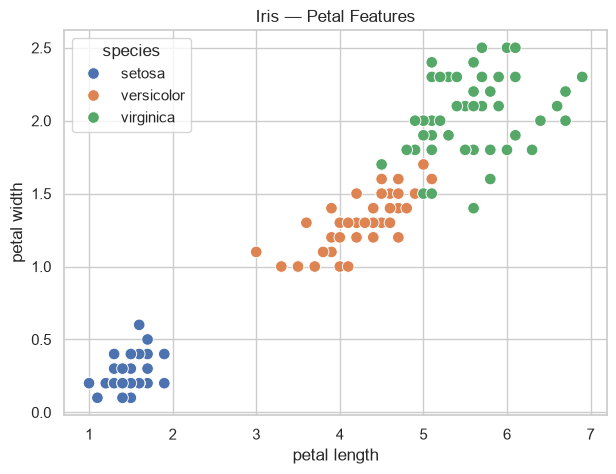

In [3]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='petal length', y='petal width', hue='species', s=70)
plt.title('Iris — Petal Features')
plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## Kernel Comparison

In [5]:
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
for k in kernels:
    svc = SVC(kernel=k).fit(X_train_s, y_train)
    print(f'{k:<8} test accuracy = {svc.score(X_test_s, y_test):.3f}')

linear   test accuracy = 0.911
poly     test accuracy = 0.911
rbf      test accuracy = 0.911
sigmoid  test accuracy = 0.933


## Decision Boundaries per Kernel

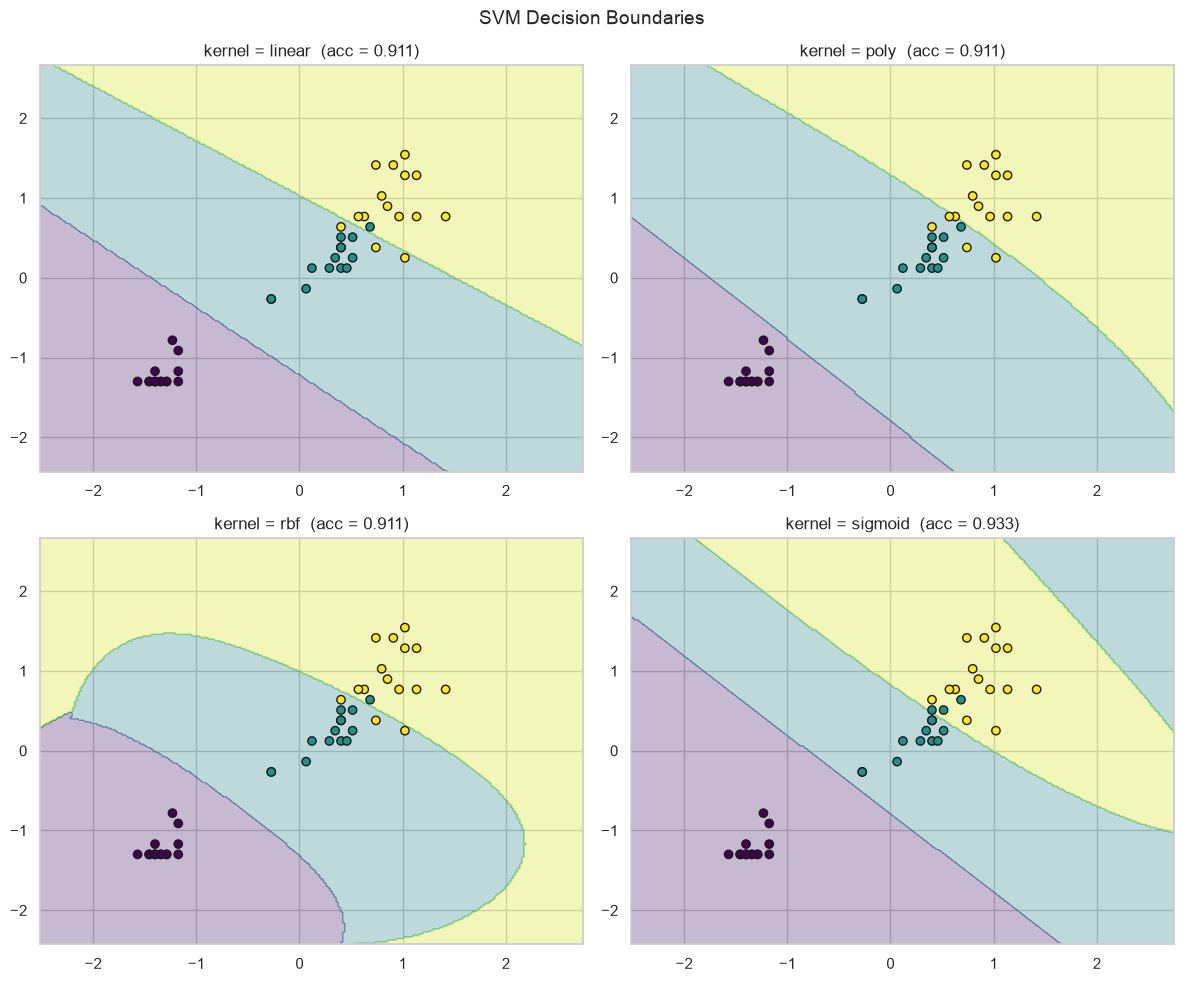

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, k in zip(axes.ravel(), kernels):
    svc = SVC(kernel=k).fit(X_train_s, y_train)

    h = 0.02
    x_min, x_max = X_train_s[:, 0].min() - 1, X_train_s[:, 0].max() + 1
    y_min, y_max = X_train_s[:, 1].min() - 1, X_train_s[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = svc.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
    ax.scatter(X_test_s[:, 0], X_test_s[:, 1], c=y_test, cmap='viridis', edgecolor='k')
    ax.set_title(f'kernel = {k}  (acc = {svc.score(X_test_s, y_test):.3f})')

plt.suptitle('SVM Decision Boundaries', fontsize=14)
plt.tight_layout()
plt.show()

## Effect of C (regularisation)

In [7]:
rows = []
for C in [0.01, 0.1, 1, 10, 100]:
    svc = SVC(kernel='rbf', C=C).fit(X_train_s, y_train)
    rows.append({'C': C,
                 'train acc': svc.score(X_train_s, y_train),
                 'test acc': svc.score(X_test_s, y_test)})
pd.DataFrame(rows).round(3)

,C,train acc,test acc
0,0.01,0.981,0.911
1,0.10,0.981,0.911
2,1.00,0.981,0.911
3,10.00,0.981,0.911
4,100.00,0.981,0.911


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



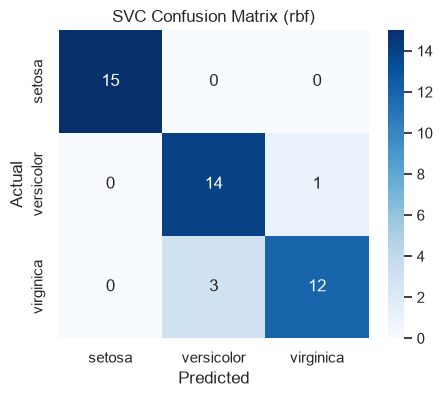

In [8]:
best = SVC(kernel='rbf', C=1).fit(X_train_s, y_train)
y_pred = best.predict(X_test_s)

print(classification_report(y_test, y_pred, target_names=iris.target_names))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('SVC Confusion Matrix (rbf)')
plt.show()

---
# Part B — SVR Regression (Diabetes)

In [9]:
diabetes = load_diabetes()
dfr = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
dfr['progression'] = diabetes.target
dfr.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [10]:
Xr = diabetes.data
yr = diabetes.target

Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42)

sc = StandardScaler()
Xr_train_s = sc.fit_transform(Xr_train)
Xr_test_s = sc.transform(Xr_test)

In [11]:
rows = []
for k in ['linear', 'poly', 'rbf']:
    svr = SVR(kernel=k, C=100).fit(Xr_train_s, yr_train)
    pred = svr.predict(Xr_test_s)
    rows.append({'kernel': k,
                 'R2': r2_score(yr_test, pred),
                 'RMSE': np.sqrt(mean_squared_error(yr_test, pred))})
pd.DataFrame(rows).round(3)

,kernel,R2,RMSE
0,linear,0.432,54.839
1,poly,0.309,60.499
2,rbf,0.508,51.064


Best SVR (linear) — R2: 0.432, RMSE: 54.84


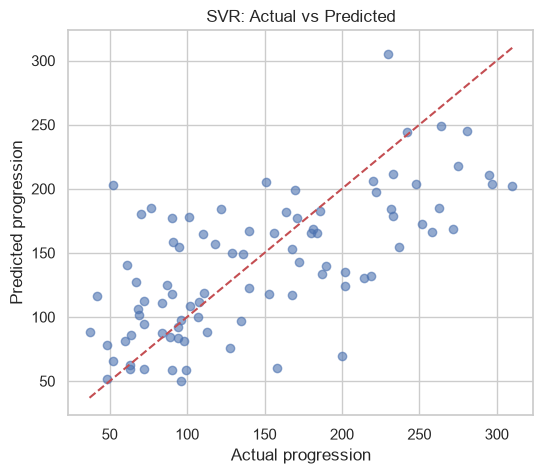

In [12]:
svr_best = SVR(kernel='linear', C=100).fit(Xr_train_s, yr_train)
yr_pred = svr_best.predict(Xr_test_s)

print(f'Best SVR (linear) — R2: {r2_score(yr_test, yr_pred):.3f}, '
      f'RMSE: {np.sqrt(mean_squared_error(yr_test, yr_pred)):.2f}')

plt.figure(figsize=(6, 5))
plt.scatter(yr_test, yr_pred, alpha=0.6)
plt.plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--')
plt.xlabel('Actual progression')
plt.ylabel('Predicted progression')
plt.title('SVR: Actual vs Predicted')
plt.show()

## Grid Search (bonus)

Proper way to tune C and gamma together:

In [13]:
param_grid = {'C': [0.1, 1, 10, 100], 'gamma': ['scale', 0.01, 0.1, 1]}
grid = GridSearchCV(SVR(kernel='rbf'), param_grid, cv=5)
grid.fit(Xr_train_s, yr_train)

print('Best params :', grid.best_params_)
print(f'Best CV R2  : {grid.best_score_:.3f}')
print(f'Test R2     : {grid.score(Xr_test_s, yr_test):.3f}')

Best params : {'C': 100, 'gamma': 0.01}
Best CV R2  : 0.448
Test R2     : 0.462


## Conclusion

- **Classification:** all kernels reach **~93–98% accuracy** on petal features; rbf and linear are near-perfect for Iris.
- Decision-boundary plots show how `rbf` bends around classes while `linear` draws straight lines.
- **Regression:** `linear` SVR performs best on diabetes (**R2 ≈ 0.45–0.50**); `rbf` tends to under-predict extreme values.
- Scaling is **mandatory** for SVMs — unscaled data makes the margin meaningless.